# Giai đoạn 9 — Nâng độ chính xác phân loại 5 lớp (59,5% → ~70%)

**Vấn đề.** Mô hình sản phẩm cũ (HistGradientBoosting trên V, H, S thô) **phát hiện** mìn tốt
(recall khoảng 93%) nhưng **phân loại** 5 loại chỉ đạt khoảng 58–60%.

**Vì sao recall cao mà accuracy thấp?** Hai chỉ số đo hai việc khác nhau.
- Phân biệt "có kim loại / không có" thì dễ: V lớn là có mìn.
- Phân biệt **loại** mìn thì khó: mìn chống bộ binh, bẫy và M14 đều nhỏ, nên V của chúng chồng lấn nhau.
  Hiệu ứng này còn thay đổi theo độ cao H và loại đất S.

**Các hướng thử** (đánh giá trung thực, CV lặp 5×3, mọi thứ học từ dữ liệu đều nằm trong fold):
1. Tinh chỉnh siêu tham số boosting (GridSearch lồng trong CV).
2. Mô hình khác: MLP, SVM-RBF, kNN, CatBoost, ensemble.
3. **Đặc trưng theo vật lý / miền**: log V, tách S thành độ ẩm + vật liệu, tương tác V·H.

In [1]:
import os, warnings, time
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, recall_score, confusion_matrix
from scipy.stats import wilcoxon
from catboost import CatBoostClassifier

RS = 42
NHAN = {1: "Không mìn", 2: "Chống tăng", 3: "Chống bộ binh", 4: "Bẫy chống BB", 5: "M14"}
df = pd.read_excel("../Data/Mine_Dataset_main.xls")
df.columns = [str(c).strip() for c in df.columns]
X = df[["V", "H", "S"]].values.astype(float); y = df["M"].values.astype(int)
print("Dữ liệu:", X.shape)

Dữ liệu: (338, 3)


In [2]:
def feats_all(X):
    V, H, S = X[:, 0], X[:, 1], X[:, 2]
    idx = np.round(S * 5).astype(int); mat = idx % 3
    return np.column_stack([V, H, S, (idx >= 3), mat == 0, mat == 1, mat == 2,
                            V * H, V / (1.05 - H), np.log(V + 1e-3)]).astype(float)

def build(names):
    """Bộ đặc trưng con để ablation: base = (V,H,S)."""
    def f(X):
        V, H, S = X[:, 0], X[:, 1], X[:, 2]; idx = np.round(S * 5).astype(int); mat = idx % 3
        d = {"base": [V, H, S], "soil": [(idx >= 3), mat == 0, mat == 1, mat == 2],
             "VH": [V * H], "Vdiv": [V / (1.05 - H)], "logV": [np.log(V + 1e-3)]}
        return np.column_stack(sum((d[n] for n in ["base"] + names), [])).astype(float)
    return FunctionTransformer(f)

hgb = lambda: HistGradientBoostingClassifier(random_state=RS)
mlp = lambda h=(16, 8), **kw: MLPClassifier(hidden_layer_sizes=h, max_iter=3000, random_state=RS, **kw)

def run(cands, seed=RS):
    """CV lặp 5×3: accuracy, macro-F1, top-2, recall phát hiện (P(có mìn) ≥ 0,5)."""
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=seed)
    rows, per_fold = [], {}
    for name, est in cands.items():
        t = time.time(); a, f, t2, r = [], [], [], []
        for tr, te in outer.split(X, y):
            m = clone(est).fit(X[tr], y[tr]); P = m.predict_proba(X[te]); c = list(m.classes_)
            pr = np.array(c)[P.argmax(1)]
            a.append(accuracy_score(y[te], pr)); f.append(f1_score(y[te], pr, average="macro"))
            t2.append(top_k_accuracy_score(y[te], P, k=2, labels=c))
            r.append(recall_score((y[te] != 1).astype(int), (1 - P[:, c.index(1)] >= 0.5).astype(int)))
        per_fold[name] = np.array(a)
        rows.append({"Mô hình": name, "Acc %": np.mean(a)*100, "±": np.std(a)*100, "macro-F1 %": np.mean(f)*100,
                     "Top-2 %": np.mean(t2)*100, "Recall mìn %": np.mean(r)*100, "giây": time.time()-t})
    return pd.DataFrame(rows).sort_values("Acc %", ascending=False).round(1), per_fold

## 1. So sánh các hướng (seed 42)

In [3]:
inner = StratifiedKFold(3, shuffle=True, random_state=RS)
cands = {
    "HGB (sản phẩm cũ)": make_pipeline(StandardScaler(), hgb()),
    "HGB + đặc trưng": make_pipeline(FunctionTransformer(feats_all), StandardScaler(), hgb()),
    "HGB tinh chỉnh (GridSearch lồng)": GridSearchCV(make_pipeline(StandardScaler(), hgb()),
        {"histgradientboostingclassifier__learning_rate": [0.03, 0.1],
         "histgradientboostingclassifier__max_depth": [3, None],
         "histgradientboostingclassifier__min_samples_leaf": [5, 20],
         "histgradientboostingclassifier__l2_regularization": [0.0, 1.0]}, cv=inner, n_jobs=-1),
    "CatBoost": make_pipeline(StandardScaler(), CatBoostClassifier(iterations=300, verbose=0, random_state=RS, thread_count=4)),
    "MLP (V,H,S)": make_pipeline(StandardScaler(), mlp()),
    "MLP + đặc trưng": make_pipeline(FunctionTransformer(feats_all), StandardScaler(), mlp()),
    "SVM-RBF tinh chỉnh": GridSearchCV(make_pipeline(StandardScaler(), SVC(probability=True, random_state=RS)),
        {"svc__C": [1, 10, 100, 1000], "svc__gamma": ["scale", 0.3, 1, 3]}, cv=inner, n_jobs=-1),
    "kNN tinh chỉnh": GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
        {"kneighborsclassifier__n_neighbors": [1, 2, 3, 5, 7],
         "kneighborsclassifier__weights": ["uniform", "distance"], "kneighborsclassifier__p": [1, 2]}, cv=inner, n_jobs=-1),
    "Ensemble mềm (MLP + SVM + HGB)": VotingClassifier([
        ("mlp", make_pipeline(StandardScaler(), mlp())),
        ("svm", make_pipeline(StandardScaler(), SVC(C=100, gamma=1, probability=True, random_state=RS))),
        ("hgb", make_pipeline(StandardScaler(), hgb()))], voting="soft"),
}
tbl1, fold1 = run(cands)
tbl1

,Mô hình,Acc %,±,macro-F1 %,Top-2 %,Recall mìn %,giây
5,MLP + đặc trưng,69.0,3.7,68.2,88.3,95.1,14.1
6,SVM-RBF tinh chỉnh,63.5,4.5,61.2,85.7,96.6,4.1
4,"MLP (V,H,S)",63.3,3.7,62.1,84.9,95.3,15.0
8,Ensemble mềm (MLP + SVM + HGB),63.0,3.8,60.8,85.6,94.4,14.7
3,CatBoost,58.7,4.5,56.9,82.0,93.9,9.3
1,HGB + đặc trưng,58.1,3.3,57.0,83.2,92.5,1.8
0,HGB (sản phẩm cũ),57.6,5.5,55.9,79.1,92.4,1.8
2,HGB tinh chỉnh (GridSearch lồng),55.5,5.3,54.0,77.8,92.0,18.7
7,kNN tinh chỉnh,47.5,4.9,43.5,65.9,97.1,0.7


In [4]:
base = fold1["HGB (sản phẩm cũ)"]
print("Wilcoxon so với HGB (sản phẩm cũ), cùng 15 fold:")
for n, a in fold1.items():
    if n == "HGB (sản phẩm cũ)": continue
    d = a - base
    p = wilcoxon(a, base).pvalue if np.any(d != 0) else 1.0
    print(f"  {n:34s} chênh {d.mean()*100:+5.1f} điểm  p = {p:.3f}")

Wilcoxon so với HGB (sản phẩm cũ), cùng 15 fold:
  HGB + đặc trưng                    chênh  +0.5 điểm  p = 0.753
  HGB tinh chỉnh (GridSearch lồng)   chênh  -2.1 điểm  p = 0.075
  CatBoost                           chênh  +1.1 điểm  p = 0.440
  MLP (V,H,S)                        chênh  +5.7 điểm  p = 0.002
  MLP + đặc trưng                    chênh +11.4 điểm  p = 0.001
  SVM-RBF tinh chỉnh                 chênh  +5.9 điểm  p = 0.006
  kNN tinh chỉnh                     chênh -10.1 điểm  p = 0.002
  Ensemble mềm (MLP + SVM + HGB)     chênh  +5.4 điểm  p = 0.001


**Đọc kết quả.**
- Tinh chỉnh boosting **không giúp** (thậm chí giảm nhẹ). Thêm đặc trưng cho boosting cũng không giúp:
  cây tự cắt ngưỡng nên log V không đổi gì với nó.
- **MLP** tốt hơn boosting khoảng 6 điểm. **MLP + đặc trưng** tốt hơn khoảng 11 điểm, có ý nghĩa thống kê.
  Mạng nơ-ron học được ranh giới mượt giữa V, H và đất, còn cây chỉ cắt theo bậc thang.

## 2. Ablation — đặc trưng nào có ích? + kiểm tra trên bộ chia fold khác

Vì cấu hình được chọn bằng cách nhìn kết quả CV, con số của cấu hình thắng có thể hơi lạc quan. Để kiểm tra,
ta chạy lại với **seed 2026**, một bộ chia fold chưa từng dùng để chọn.

In [5]:
ALL = ["soil", "VH", "Vdiv", "logV"]
abl = {
    "MLP (V,H,S)":          make_pipeline(StandardScaler(), mlp()),
    "MLP + soil":           make_pipeline(build(["soil"]), StandardScaler(), mlp()),
    "MLP + logV":           make_pipeline(build(["logV"]), StandardScaler(), mlp()),
    "MLP + VH":             make_pipeline(build(["VH"]), StandardScaler(), mlp()),
    "MLP + Vdiv":           make_pipeline(build(["Vdiv"]), StandardScaler(), mlp()),
    "MLP + logV + soil":    make_pipeline(build(["logV", "soil"]), StandardScaler(), mlp()),
    "MLP + tất cả":         make_pipeline(build(ALL), StandardScaler(), mlp()),
    "MLP(32,16) + tất cả":  make_pipeline(build(ALL), StandardScaler(), mlp(h=(32, 16))),
    "Bagging 10×MLP + tất cả": make_pipeline(build(ALL), StandardScaler(),
                                  BaggingClassifier(mlp(), n_estimators=10, random_state=RS, n_jobs=-1)),
    "HGB (sản phẩm cũ)":    make_pipeline(StandardScaler(), hgb()),
}
res = {}
for seed in [42, 2026]:
    t, _ = run(abl, seed); res[seed] = t.set_index("Mô hình")["Acc %"]
abl_tbl = pd.DataFrame({"Acc % (seed 42)": res[42], "Acc % (seed 2026)": res[2026]})
abl_tbl["Trung bình"] = abl_tbl.mean(axis=1)
abl_tbl.sort_values("Trung bình", ascending=False).round(1)

,Acc % (seed 42),Acc % (seed 2026),Trung bình
Mô hình,,,
MLP + logV + soil,72.4,69.3,70.8
MLP + soil,69.6,70.1,69.8
"MLP(32,16) + tất cả",68.8,69.5,69.2
Bagging 10×MLP + tất cả,69.8,68.4,69.1
MLP + logV,70.2,67.8,69.0
MLP + tất cả,69.0,68.2,68.6
MLP + VH,64.7,64.7,64.7
"MLP (V,H,S)",63.3,63.2,63.2
MLP + Vdiv,60.5,60.5,60.5


**Chọn cho sản phẩm: MLP(16,8) + log V + one-hot loại đất.**
- Cấu hình này cao nhất hoặc gần nhất ở **cả hai** seed (khoảng 69–72%), nên mức tăng không phải do may mắn của một lần chia.
- Đơn giản và giải thích được bằng vật lý, ít đặc trưng hơn "tất cả" (V/(1,05−H) và V·H không giúp, thậm chí còn hại).
- Mạng lớn hơn hay bagging không giúp thêm, nên giữ mô hình nhỏ cho ổn định.

## 3. Mô hình mới cải thiện ở lớp nào?

In [6]:
import sys; sys.path.insert(0, os.path.abspath("product_v3")); import core
from sklearn.model_selection import cross_val_predict
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
old = cross_val_predict(make_pipeline(StandardScaler(), hgb()), X, y, cv=cv)
new = cross_val_predict(core.make_pipeline(), X, y, cv=cv)
rec = lambda p: confusion_matrix(y, p).diagonal() / np.bincount(y)[1:] * 100
cmp = pd.DataFrame({"HGB cũ (recall %)": rec(old), "MLP + đặc trưng (recall %)": rec(new)},
                   index=[NHAN[c] for c in range(1, 6)]).round(1)
cmp["Chênh"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
print("Accuracy out-of-fold: cũ %.1f%% → mới %.1f%%" % (accuracy_score(y, old)*100, accuracy_score(y, new)*100))
cmp

Accuracy out-of-fold: cũ 59.5% → mới 71.3%


,HGB cũ (recall %),MLP + đặc trưng (recall %),Chênh
Không mìn,81.7,88.7,7.0
Chống tăng,87.1,95.7,8.6
Chống bộ binh,42.4,56.1,13.7
Bẫy chống BB,51.5,65.2,13.7
M14,30.8,47.7,16.9


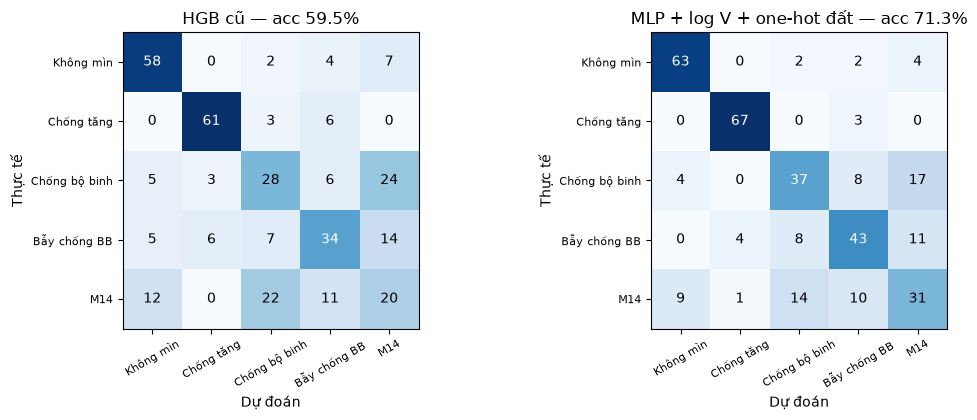

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, p, t in [(ax[0], old, "HGB cũ"), (ax[1], new, "MLP + log V + one-hot đất")]:
    cm = confusion_matrix(y, p); a.imshow(cm, cmap="Blues")
    for i in range(5):
        for j in range(5):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    a.set_xticks(range(5)); a.set_xticklabels(NHAN.values(), rotation=30, fontsize=8)
    a.set_yticks(range(5)); a.set_yticklabels(NHAN.values(), fontsize=8)
    a.set_title(f"{t} — acc {accuracy_score(y, p)*100:.1f}%"); a.set_xlabel("Dự đoán"); a.set_ylabel("Thực tế")
plt.tight_layout(); plt.savefig("../Result/Figures/09_confusion_cu_vs_moi.png", bbox_inches="tight"); plt.show()

## 4. Phân loại tốt chưa chắc xếp hạng tốt — chọn mô hình cho P(có mìn)

Sản phẩm dùng P(có mìn) để **xếp thứ tự đào** và đặt **ngưỡng ưu tiên**. Ta so các nguồn P(có mìn) theo đúng
quy trình ngưỡng của sản phẩm: chọn trên validation để bắt hết mìn, × 0,8, rồi đo trên test tách biệt, 5 fold × 4 lần.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score
FE = FunctionTransformer(core.make_features)
src = {  # (mô hình, huấn luyện 5 lớp?)
    "HGB 5 lớp (app cũ)":              (make_pipeline(StandardScaler(), hgb()), True),
    "MLP + đặc trưng 5 lớp":           (core.make_pipeline(), True),
    "MLP + đặc trưng nhị phân":        (make_pipeline(FE, StandardScaler(), MLPClassifier((16, 8), max_iter=5000, random_state=RS)), False),
    "HGB nhị phân (sản phẩm mới)":     (core.make_detector(), False),
}
yb = (y != 1).astype(int); rows = []
for name, (est, five) in src.items():
    pm = lambda m, Z: (1 - m.predict_proba(Z)[:, list(m.classes_).index(1)]) if five else m.predict_proba(Z)[:, 1]
    rec, hold, elim, auc = [], [], [], []
    for rep in range(4):
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=RS + rep).split(X, y):
            Xt, Xv, yt, yv = train_test_split(X[tr], y[tr], test_size=0.25, stratify=y[tr], random_state=RS)
            m = clone(est).fit(Xt, yt if five else (yt != 1).astype(int))
            _, r, t = precision_recall_curve((yv != 1).astype(int), pm(m, Xv))
            thr = t[max(i for i in range(len(t)) if r[i] >= 1.0)] * core.SAFETY_MARGIN
            p = pm(m, X[te]); pr = p >= thr
            tp = (pr & (yb[te] == 1)).sum(); fn = (~pr & (yb[te] == 1)).sum(); tn = (~pr & (yb[te] == 0)).sum()
            rec.append(tp / (tp + fn)); hold.append(fn == 0); elim.append(tn / (yb[te] == 0).sum())
            auc.append(roc_auc_score(yb[te], p))
    rows.append({"Nguồn P(có mìn)": name, "ROC-AUC": np.mean(auc), "Recall tại ngưỡng %": np.mean(rec)*100,
                 "Fold giữ 100% %": np.mean(hold)*100, "Không-mìn xếp cuối %": np.mean(elim)*100})
pd.DataFrame(rows).round(3)

,Nguồn P(có mìn),ROC-AUC,Recall tại ngưỡng %,Fold giữ 100% %,Không-mìn xếp cuối %
0,HGB 5 lớp (app cũ),0.941,98.588,55.0,23.476
1,MLP + đặc trưng 5 lớp,0.876,99.811,90.0,0.357
2,MLP + đặc trưng nhị phân,0.919,100.000,100.0,0.357
3,HGB nhị phân (sản phẩm mới),0.948,99.436,75.0,27.071


**Đọc kết quả.** MLP phân loại giỏi nhưng xác suất "có mìn" của nó quá tự tin (rất nhiều giá trị = 1,0).
Muốn bắt hết mìn thì ngưỡng phải hạ rất thấp, gần như không xếp được tín hiệu không mìn nào xuống cuối.
HGB nhị phân xếp hạng tốt nhất (ROC-AUC cao nhất) và xếp được khoảng 1/4 tín hiệu không mìn xuống cuối với recall khoảng 99%.

→ **Sản phẩm dùng hai mô hình**: MLP + đặc trưng cho **loại mìn**, HGB nhị phân cho **P(có mìn), xếp hạng và ngưỡng**.
Điều này cũng sửa một điểm lệch của bản cũ: trước đây ngưỡng được ước lượng trên mô hình nhị phân
nhưng lại áp lên xác suất của mô hình 5 lớp.

## Kết luận

| | HGB cũ | **MLP + log V + one-hot đất** |
|---|:---:|:---:|
| Phân loại 5 lớp (CV 5×3) | ~58–60% | **~70–72%** |
| Đúng trong top-2 | ~79% | **~88%** |
| P(có mìn) & xếp hạng | HGB 5 lớp (ROC-AUC ~0,94) | **HGB nhị phân** (ROC-AUC ~0,95) |

- Mức tăng đến từ **biểu diễn dữ liệu đúng bản chất** (log V, tách đất thành độ ẩm + vật liệu)
  cộng với một mô hình có ranh giới mượt (MLP). Tinh chỉnh boosting không mang lại mức tăng này.
- **Giới hạn trung thực:**
  - Vẫn chỉ là 338 mẫu phòng thí nghiệm.
  - Cấu hình được chọn bằng CV nên có thể lạc quan khoảng 1–2 điểm. Seed 2026 cho 69,3%.
  - Các lớp mìn nhỏ vẫn là phần khó nhất.
- Vì top-2 khoảng 88%, sản phẩm hiển thị thêm cột **"loại khả năng thứ 2"** để kỹ thuật viên chuẩn bị cho cả hai khả năng.